In [ ]:
import zipfile

with zipfile.ZipFile("archive.zip", "r") as zip_file:
    print(zip_file.namelist())

['train.csv']


In [ ]:
import zipfile

with zipfile.ZipFile("archive.zip", "r") as zip_file:
    zip_file.extractall("Titanic_Dataset")

print("Dataset successfully extracted!")

Dataset successfully extracted!


In [ ]:
import os

print(os.listdir("Titanic_Dataset"))

['train.csv']


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
df = pd.read_csv("Titanic_Dataset/train.csv")

print("Titanic Dataset Loaded Successfully!")

Titanic Dataset Loaded Successfully!


In [ ]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
df.shape

(891, 12)

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [ ]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(891, 12)

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [ ]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df_clean = df.copy()

print("Data copy created successfully!")

Data copy created successfully!


In [ ]:
# Fill missing Age with median
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())

# Fill missing Embarked with mode
df_clean["Embarked"] = df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])

# Remove Cabin column if more than 50% values are missing
if df_clean["Cabin"].isnull().mean() > 0.5:
    df_clean.drop("Cabin", axis=1, inplace=True)

print("Missing values handled successfully!")

Missing values handled successfully!


C:\Users\athar\AppData\Local\Temp\ipykernel_10996\3969772965.py:9: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.drop("Cabin", axis=1, inplace=True)


In [ ]:
df_clean = df_clean.drop_duplicates()

print("Duplicate records removed!")

Duplicate records removed!


In [ ]:
print(df_clean.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [ ]:
print("Total Passengers:", len(df_clean))

Total Passengers: 891


In [ ]:
print("Total Survivors:", df_clean["Survived"].sum())

Total Survivors: 342


In [ ]:
print("Total Deaths:", (df_clean["Survived"] == 0).sum())

Total Deaths: 549


In [ ]:
survival_rate = df_clean["Survived"].mean() * 100

print("Survival Rate:", round(survival_rate, 2), "%")

Survival Rate: 38.38 %


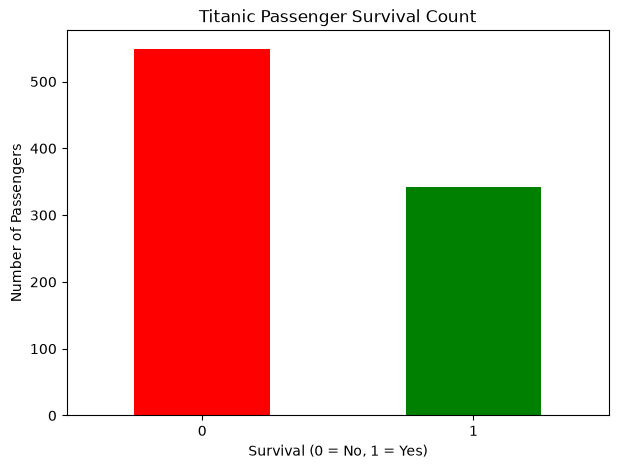

In [ ]:
survival_counts = df_clean["Survived"].value_counts()

survival_counts.plot(
    kind="bar",
    color=["red", "green"],
    figsize=(7,5)
)

plt.title("Titanic Passenger Survival Count")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.show()

In [ ]:
gender_survival = df_clean.groupby("Sex")["Survived"].sum()

print(gender_survival)

Sex
female    233
male      109
Name: Survived, dtype: int64


In [ ]:
gender_percentage = df_clean.groupby("Sex")["Survived"].mean() * 100

print(gender_percentage)

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


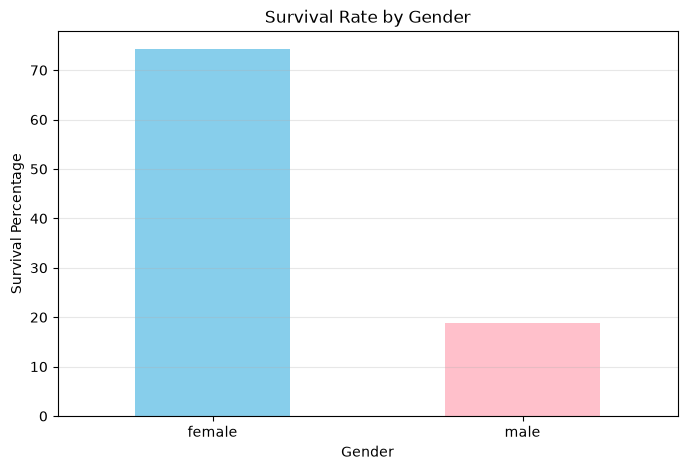

In [ ]:
gender_percentage.plot(
    kind="bar",
    color=["skyblue", "pink"],
    figsize=(8,5)
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Percentage")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
class_survival = df_clean.groupby("Pclass")["Survived"].mean() * 100

print(class_survival)

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


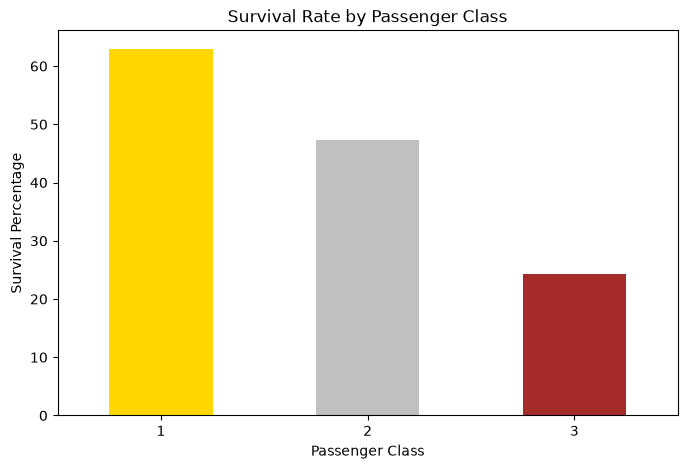

In [ ]:
class_survival.plot(
    kind="bar",
    color=["gold", "silver", "brown"],
    figsize=(8,5)
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Percentage")
plt.xticks(rotation=0)
plt.show()

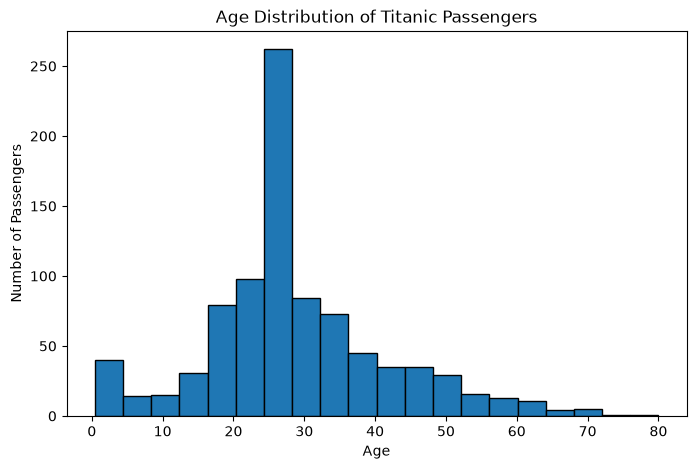

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df_clean["Age"], bins=20, edgecolor="black")

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

In [ ]:
embarked_survival = df_clean.groupby("Embarked")["Survived"].mean() * 100

print(embarked_survival)

Embarked
C    55.357143
Q    38.961039
S    33.900929
Name: Survived, dtype: float64


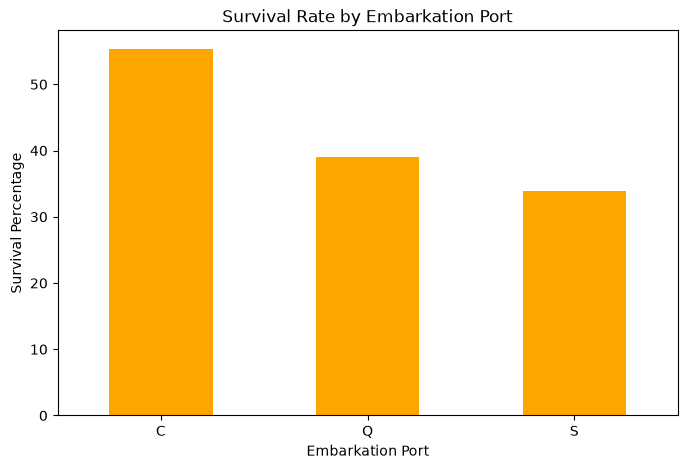

In [ ]:
embarked_survival.plot(
    kind="bar",
    color="orange",
    figsize=(8,5)
)

plt.title("Survival Rate by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Survival Percentage")
plt.xticks(rotation=0)
plt.show()

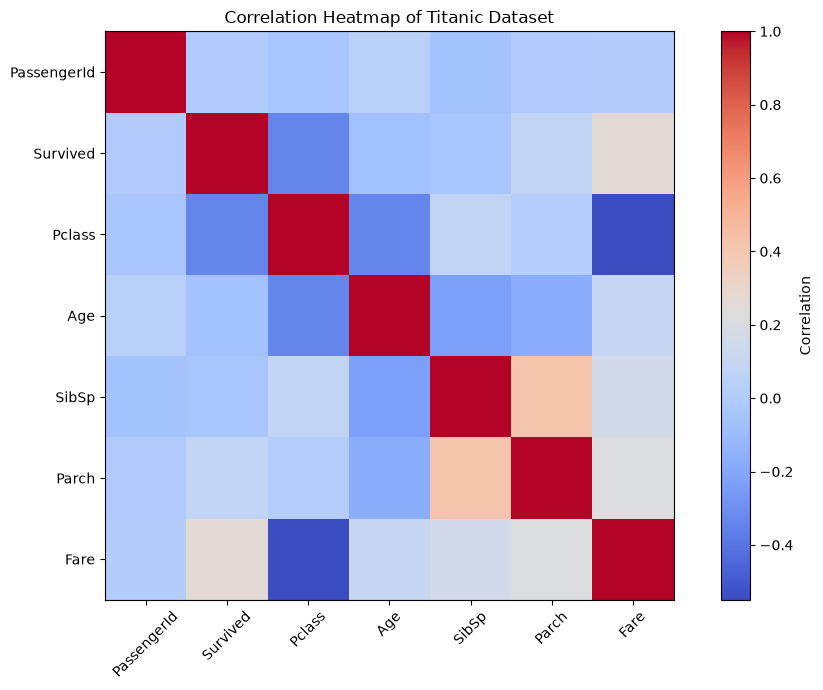

In [ ]:
import matplotlib.pyplot as plt

correlation = df_clean.corr(numeric_only=True)

plt.figure(figsize=(10, 7))

plt.imshow(correlation, cmap="coolwarm", interpolation="nearest")

plt.colorbar(label="Correlation")

plt.xticks(range(len(correlation.columns)),
           correlation.columns, rotation=45)

plt.yticks(range(len(correlation.columns)),
           correlation.columns)

plt.title("Correlation Heatmap of Titanic Dataset")

plt.tight_layout()
plt.show()

In [ ]:
df_clean["FamilySize"] = (
    df_clean["SibSp"] + df_clean["Parch"] + 1
)

family_survival = df_clean.groupby("FamilySize")["Survived"].mean() * 100

print(family_survival)

FamilySize
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64


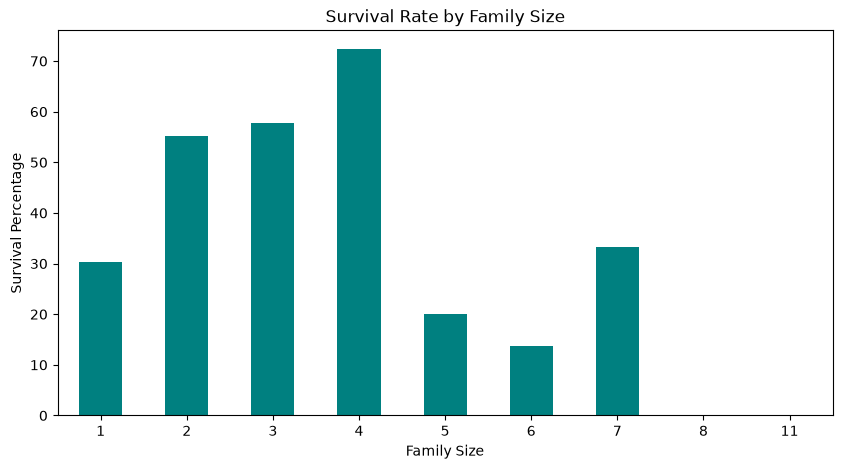

In [ ]:
family_survival.plot(
    kind="bar",
    figsize=(10,5),
    color="teal"
)

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Percentage")
plt.xticks(rotation=0)
plt.show()

In [ ]:
print("========== TITANIC DATA ANALYSIS ==========")

print("Total Passengers:", len(df_clean))

print("Total Survivors:",
      df_clean["Survived"].sum())

print("Total Deaths:",
      (df_clean["Survived"] == 0).sum())

print("Overall Survival Rate:",
      round(df_clean["Survived"].mean() * 100, 2), "%")

print("Male Passengers:",
      (df_clean["Sex"] == "male").sum())

print("Female Passengers:",
      (df_clean["Sex"] == "female").sum())

print("===========================================")

========== TITANIC DATA ANALYSIS ==========
Total Passengers: 891
Total Survivors: 342
Total Deaths: 549
Overall Survival Rate: 38.38 %
Male Passengers: 577
Female Passengers: 314


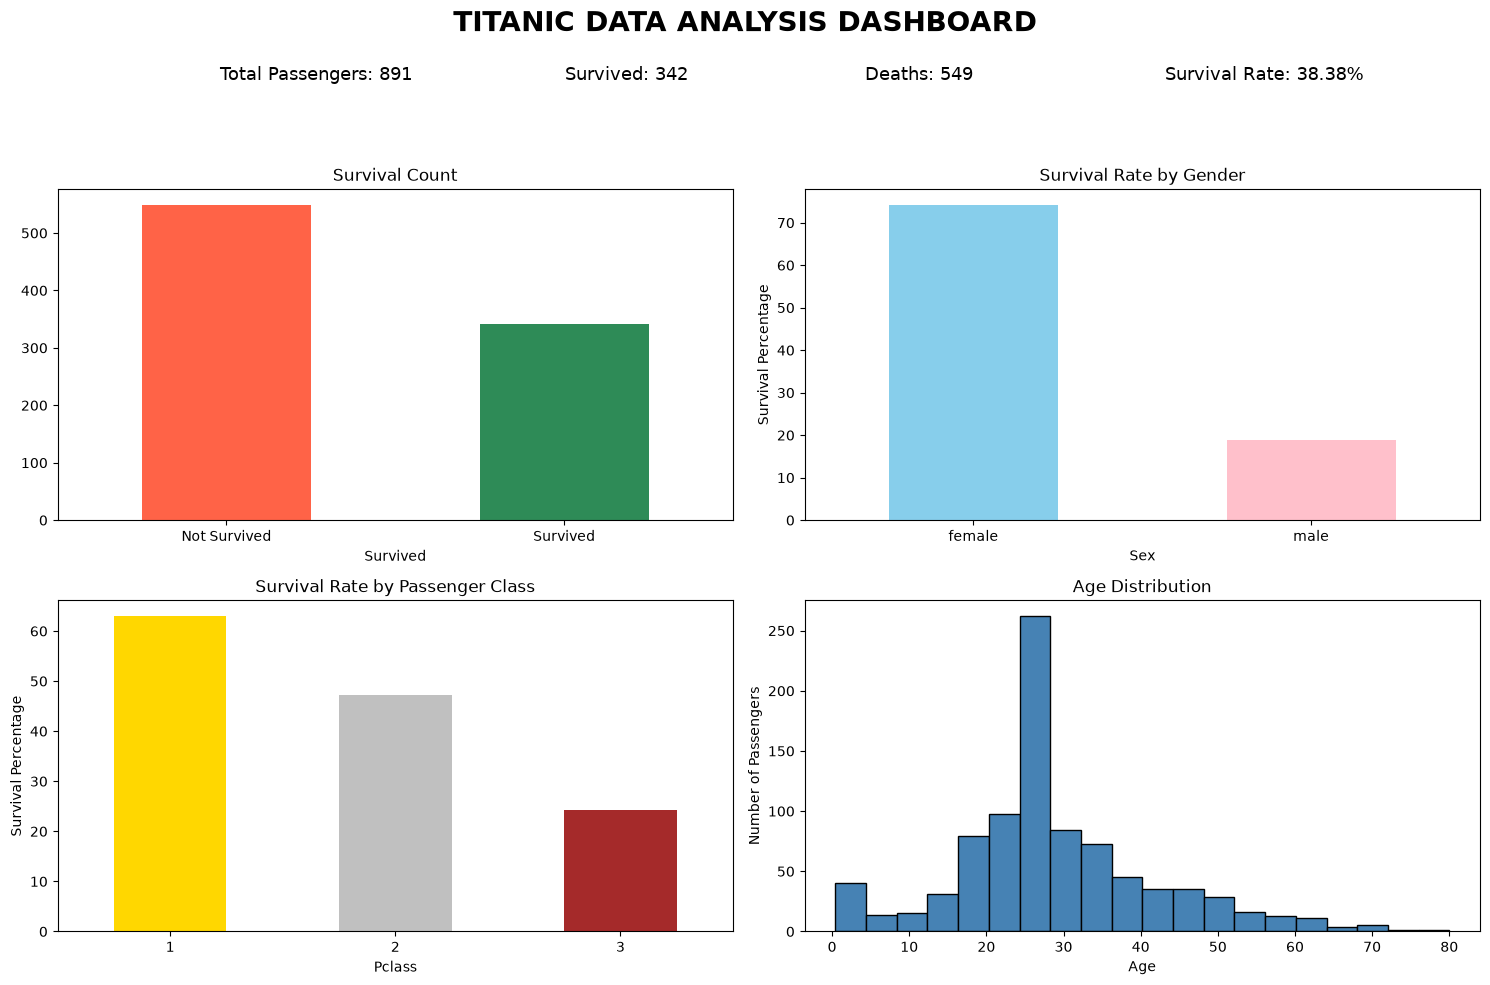

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Calculate important statistics
total = len(df_clean)
survived = df_clean["Survived"].sum()
dead = total - survived
rate = (survived / total) * 100

# Create dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

fig.suptitle(
    "TITANIC DATA ANALYSIS DASHBOARD",
    fontsize=20,
    fontweight="bold"
)

# KPI summary
fig.text(0.15, 0.91, f"Total Passengers: {total}", fontsize=13)
fig.text(0.38, 0.91, f"Survived: {survived}", fontsize=13)
fig.text(0.58, 0.91, f"Deaths: {dead}", fontsize=13)
fig.text(0.78, 0.91, f"Survival Rate: {rate:.2f}%", fontsize=13)

# 1. Survival Count
df_clean["Survived"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0, 0],
    color=["tomato", "seagreen"]
)
axes[0, 0].set_title("Survival Count")
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_xticklabels(["Not Survived", "Survived"], rotation=0)

# 2. Gender Survival
(df_clean.groupby("Sex")["Survived"].mean() * 100).plot(
    kind="bar", ax=axes[0, 1],
    color=["skyblue", "pink"]
)
axes[0, 1].set_title("Survival Rate by Gender")
axes[0, 1].set_ylabel("Survival Percentage")
axes[0, 1].tick_params(axis="x", rotation=0)

# 3. Passenger Class
(df_clean.groupby("Pclass")["Survived"].mean() * 100).plot(
    kind="bar", ax=axes[1, 0],
    color=["gold", "silver", "brown"]
)
axes[1, 0].set_title("Survival Rate by Passenger Class")
axes[1, 0].set_ylabel("Survival Percentage")
axes[1, 0].tick_params(axis="x", rotation=0)

# 4. Age Distribution
axes[1, 1].hist(
    df_clean["Age"],
    bins=20,
    color="steelblue",
    edgecolor="black"
)
axes[1, 1].set_title("Age Distribution")
axes[1, 1].set_xlabel("Age")
axes[1, 1].set_ylabel("Number of Passengers")

plt.tight_layout(rect=[0, 0, 1, 0.88])

plt.savefig("Titanic_Dashboard.png", dpi=300)

plt.show()